In [4]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from scipy.optimize import curve_fit
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# Full calibration and benchmarking of robust gateset

First, we activate the IBM service we are going to be using.

In [5]:
from qiskit_ibm_runtime import QiskitRuntimeService, Session, SamplerV2 as Sampler

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
service = QiskitRuntimeService(token=IBM_TOKEN, channel="ibm_quantum")

In [6]:
from qiskit_ibm_provider import IBMProvider

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
provider = IBMProvider(token=IBM_TOKEN, instance="ibm-q-ornl/ornl/phy147")

And we get backend information.

In [7]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.FakeManila()
backend = service.get_backend("ibm_nazca")
dt = backend.configuration().dt * ns

# desired_duration = 225 # dt
desired_duration = 120  # dt

# Can be acquired with backend.configuration().timing_constraints['granularity']
# granularity = 16
granularity = backend.configuration().timing_constraints["granularity"]

GATE_TIME_SI_UNITS = desired_duration * dt / ns
# duration = ps.qiskit_closest_multiple_of_16(GATE_TIME_SI_UNITS, backend)
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 120)

Then we load our robust gateset.

In [8]:
pico_a = ps.from_csv(
    "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_R1e-3.csv"
)
pico_gates = {key: row for key, row in zip(["x1", "x2", "sx1", "sx2"], pico_a)}

And we define a Guassian gateset to which we are going to compare.

In [9]:
default_gates = {
    "x1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "x2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "sx1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
    "sx2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
}

The maximum aplitude allowed by qiskit pulse is the `amp` factor times the amplitude of the signal we are sending.

In [47]:
signal = pico_gates["x1"]
x1_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

signal = pico_gates["sx1"]
sx1_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

print(x1_max, sx1_max)
print(1 / x1_max, 1 / sx1_max)

0.2963917651303308 0.30449285439741686
3.37391290058371 3.284149317654672


In [48]:
signal = pico_gates["x2"]
x2_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

signal = pico_gates["sx2"]
sx2_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

print(x2_max, sx2_max)
print(1 / x2_max, 1 / sx2_max)

0.33116668929519094 0.33598808220773346
3.019627372934943 2.976296044279701


So we can bump up the `drive_amps` closer to -3 and 3.

## Rough amplitude calibration

We choose two qubits with good T1/T2 times and a range of amplitudes to calibrate the gates.

In [19]:
qubit0, qubit1 = 1, 2
qubit2, qubit3 = 5, 6
qubit4, qubit5 = 10, 11
drive_amps = np.linspace(-2.8, 2.8, 50)

And we create schedules with our robust gates using this range of amplitudes.

In [20]:
def get_schedules(signal, qubit: int, drive_amps: list[float]):
    schedules = []
    for amp in drive_amps:
        with qk.pulse.build(name=f"rabi_sched", backend=backend) as sched:
            signal_samples = ps.resample(
                duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
            )
            gate = ps.scalable_symbolic_pulse(
                duration, signal_samples, "custom", amp=amp
            )
            qk.pulse.play(gate.get_waveform(), qk.pulse.DriveChannel(qubit))
        schedules.append(sched)
    return schedules

In [21]:
robust_x1_schedules = get_schedules(pico_gates["x1"], qubit0, drive_amps)

We do the same for the Gaussian pulses.

In [22]:
gaussian_x1_schedules = get_schedules(default_gates["x1"].samples, qubit0, drive_amps)

We can use the schedules to create circuits that we can run to IBM.

In [23]:
num_qubits = backend.num_qubits
num_qubits

127

In [24]:
def get_circuits_from_scheds(schedules, num_qubits: int, qubit: int):
    circuits = []
    for i, schedule in enumerate(schedules):
        gate = qk.circuit.Gate(f"rabi", 1, [])
        cr = qk.ClassicalRegister(1, name="c")
        qr = qk.QuantumRegister(num_qubits, name="q")
        qc = qk.QuantumCircuit(qr, cr, name=f"schedule")
        qc.append(gate, [qubit])
        qc.measure(qubit, cr[0])
        qc.add_calibration(gate, (qubit,), schedule)
        circuits.append(qc)
    return circuits

In [25]:
robust_x1_circuits = get_circuits_from_scheds(robust_x1_schedules, num_qubits, qubit0)
robust_x1_circuits[0].draw(idle_wires=False)

┌──────┐┌─┐
q_1: ┤ rabi ├┤M├
     └──────┘└╥┘
c: 1/═════════╩═
              0

We can parallelize our calibration by running circuits that act on different qubits at the same time. So, we can calibrate both x gates in parallel, and both sx gates in parallel. We can also do more qubit pairs.

In [26]:
def construct_parallel_circuits(qubits: list[int], signals, drive_amps: list[float], num_qubits: int):
    assert len(qubits) == len(signals)

    qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(len(drive_amps))]
    crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(len(drive_amps))]
    qcs = [qk.QuantumCircuit(qrs[i], crs[i]) for i in range(len(drive_amps))]

    for i, (qubit, signal) in enumerate(zip(qubits, signals)):
        schedules = get_schedules(signal, qubit, drive_amps)
        circuits = get_circuits_from_scheds(schedules, num_qubits, qubit)

        for j, (qc, circuit) in enumerate(zip(qcs, circuits)):
            qc.append(circuit, qargs=qrs[j], cargs=(crs[j][i],))

            # have to add calibrations to new circuit
            gate = qk.circuit.Gate(f"rabi", 1, [])
            qc.add_calibration(gate, (qubit,), schedules[j])

    return [qc.decompose() for qc in qcs]

In [29]:
qubits = [qubit0, qubit1, qubit2, qubit3, qubit4, qubit5]
x_signals = [pico_gates["x1"], pico_gates["x2"]] * 3
sx_signals = [pico_gates["sx1"], pico_gates["sx2"]] * 3

x_parallel_circuits = construct_parallel_circuits(qubits, x_signals, drive_amps, num_qubits)
sx_parallel_circuits = construct_parallel_circuits(qubits, sx_signals, drive_amps, num_qubits)

In [30]:
x_parallel_circuits[1].draw(idle_wires=False)

┌──────┐┌─┐               
 q_1: ┤ rabi ├┤M├───────────────
      ├──────┤└╥┘┌─┐            
 q_2: ┤ rabi ├─╫─┤M├────────────
      ├──────┤ ║ └╥┘┌─┐         
 q_5: ┤ rabi ├─╫──╫─┤M├─────────
      ├──────┤ ║  ║ └╥┘┌─┐      
 q_6: ┤ rabi ├─╫──╫──╫─┤M├──────
      ├──────┤ ║  ║  ║ └╥┘┌─┐   
q_10: ┤ rabi ├─╫──╫──╫──╫─┤M├───
      ├──────┤ ║  ║  ║  ║ └╥┘┌─┐
q_11: ┤ rabi ├─╫──╫──╫──╫──╫─┤M├
      └──────┘ ║  ║  ║  ║  ║ └╥┘
 c: 6/═════════╩══╩══╩══╩══╩══╩═
               0  1  2  3  4  5

So, as you can see above, we parallelize the rough calibration by running circuits of the form above (we omit idle wires in the drawing to save space).

We can now run the calibration jobs. But first, we have to open a runtime session and save its id.

In [634]:
session = Session(backend=backend)
print(f"Session id: {session.session_id}")

Session id: crfcj0rd7s5g008xwgqg


In [ ]:
num_shots_per_point = 1024
sampler = Sampler(backend=backend, session=session)

x_parallel_jobs = sampler.run(x_parallel_circuits, shots=num_shots_per_point)
sx_parallel_jobs = sampler.run(sx_parallel_circuits, shots=num_shots_per_point)

In [183]:
x_parallel_jobs.job_id(), sx_parallel_jobs.job_id()

('crdh1axdjmqg008kfj70', 'crdh1b5mn34g0080yr20')

In [187]:
x_parallel_jobs.status(), sx_parallel_jobs.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [186]:
x_parallel_jobs = service.job("crbc0c9hjs5g008py5v0")
sx_parallel_jobs = service.job("crbc0chbs5wg008apebg")

We define the functions that will help us analyze the calibration data.

In [189]:
def get_qubit_one_counts(counts, qubit, num_qubits):
    total = 0
    for key, val in counts.items():
        if key[num_qubits - qubit - 1] == "1": # because of little-endian
            total += val
    return total

In [190]:
def get_rabi_values(job, shots, qubits):
    rabi_values = [[] for _ in range(len(qubits))] # each list element is the data for a single qubit
    result = job.result()
    for i in range(len(result)):
        counts = result[i].data.c.get_counts()
        for j in range(len(qubits)):
            rabi_values[j].append(get_qubit_one_counts(counts, j, len(qubits)) / shots)
    return rabi_values

In [191]:
x_rabi_values = get_rabi_values(x_parallel_jobs, num_shots_per_point, qubits)
sx_rabi_values = get_rabi_values(sx_parallel_jobs, num_shots_per_point, qubits)

In [192]:
def fit_function(x_values, y_values, function, init_params):
    fitparams, conv = curve_fit(function, x_values, y_values, init_params)
    y_fit = function(x_values, *fitparams)
    return fitparams, y_fit, conv

def baseline_remove(values):
    return np.array(values) - np.mean(values)

In [206]:
def get_drive_period(
    rabi_values: list[float], 
    drive_amps: list[float], 
    factor: int,
    gate_name: str = "",
    plot: bool = False, 
    qubit: int = 0,
    amplitude_max: float = 1,
    normal_params: bool = True,
):
    """factor is 2 for x gates and 4 for sx gates"""
    rabi_values = np.real(baseline_remove(rabi_values))
    
    starting_params = [1, 1, 1.3, 0.5] if normal_params else [1, 1, 1, 0.5]
    fit_params, y_fit, _ = fit_function(
        drive_amps,
        rabi_values,
        lambda x, A, B, drive_period, phi: (
            A * np.cos(2 * np.pi * x / drive_period - phi) + B
        ),
        starting_params,
    )

    drive_period = fit_params[2]  # get period of rabi oscillation
    
    if plot:
        plot_amps = amplitude_max * np.array(drive_amps)
        plt.scatter(plot_amps, rabi_values, marker="x", color="black")
        plt.plot(plot_amps, y_fit)

        plt.xlabel("Maximum pulse amplitude")
        plt.ylabel("Prob. of meas. 1 (baseline removed)")
        plt.title(f"{gate_name} calibration on qubit {qubit}")
        plt.show()

    return drive_period / factor

And we get the estimated amplitudes.

In [207]:
drive_amps = np.linspace(-1.2, 1.2, 50)
# drive_amps = np.linspace(-2.8, 2.8, 50)

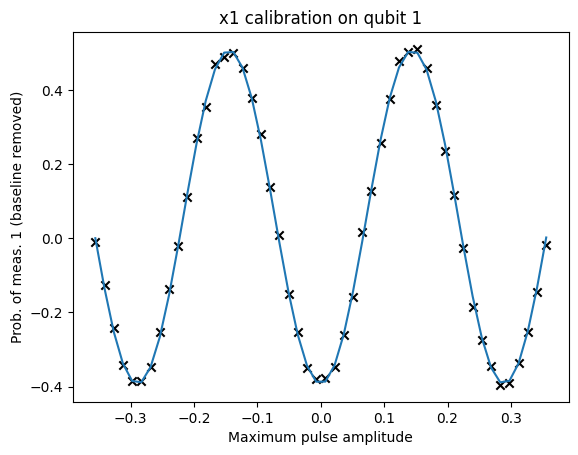

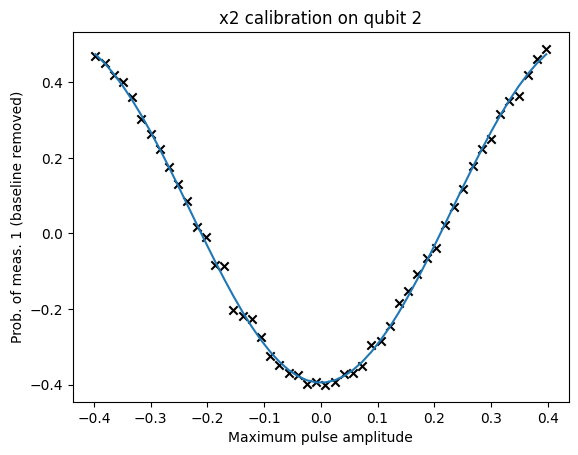

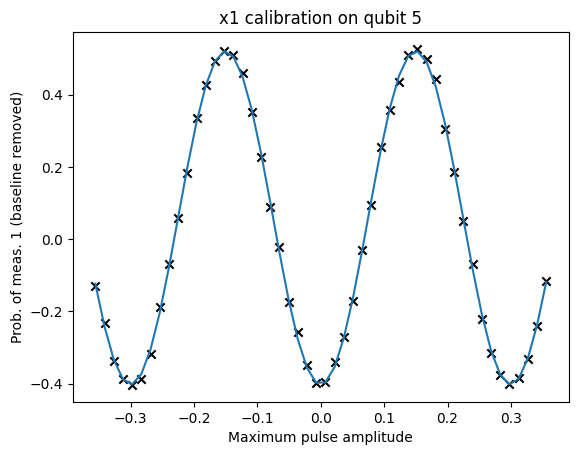

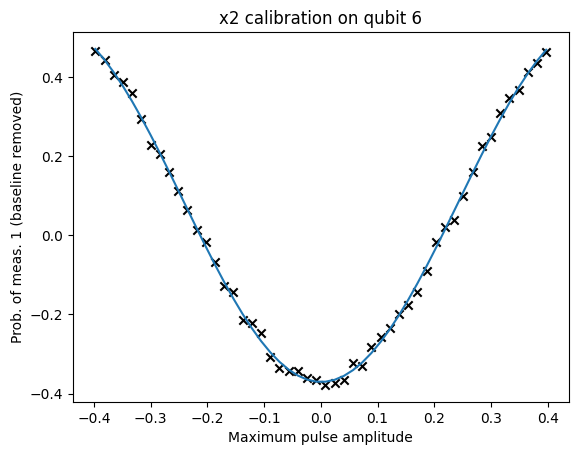

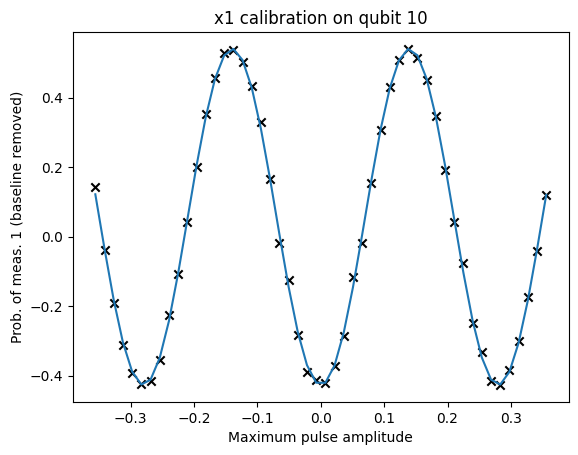

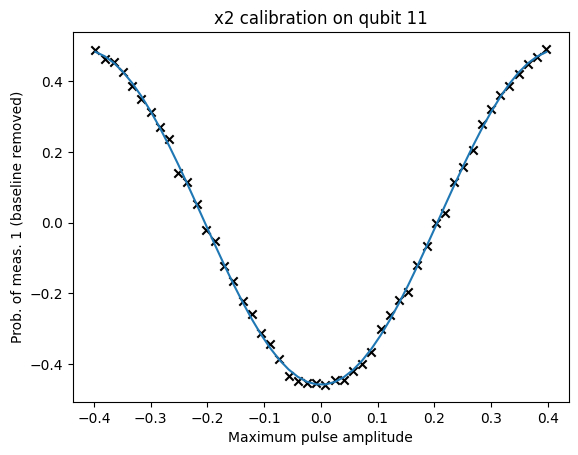

In [602]:
x_rough_amps = []
for i, (qubit, rabi) in enumerate(zip(qubits, x_rabi_values)):
    x_rough_amps.append(get_drive_period(
        rabi, 
        drive_amps, 
        2,
        gate_name=f"x{i % 2 + 1}",
        plot=True, 
        qubit=qubit, 
        amplitude_max= x1_max if i % 2 == 0 else x2_max,
    ))

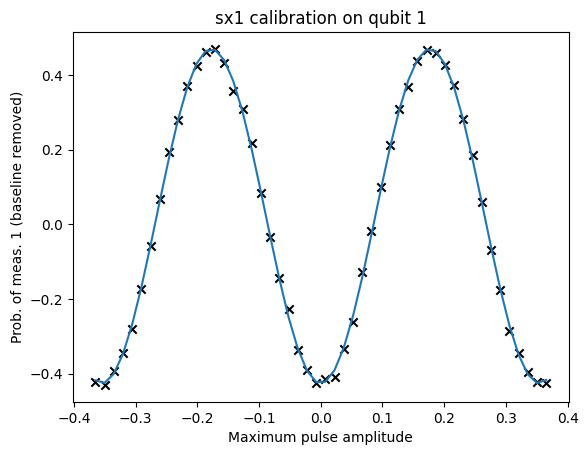

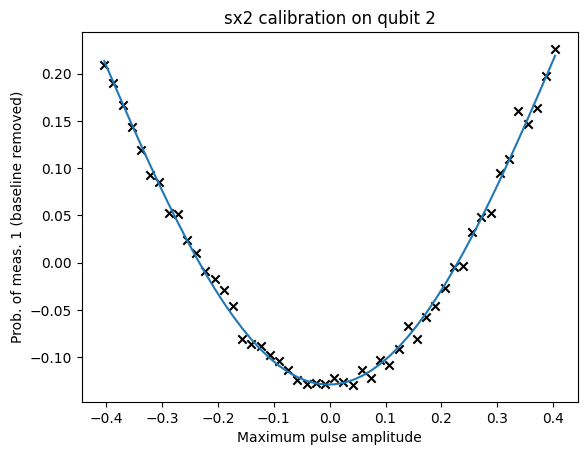

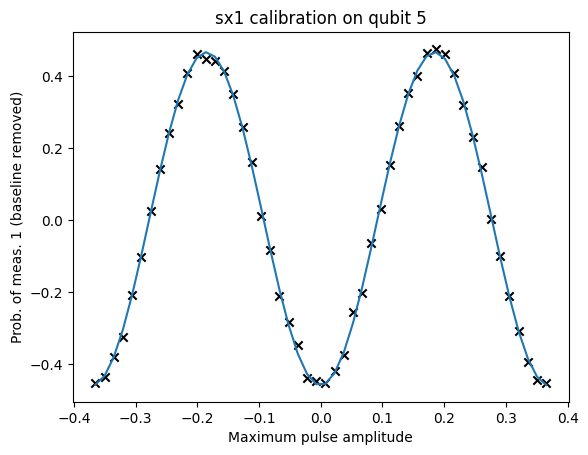

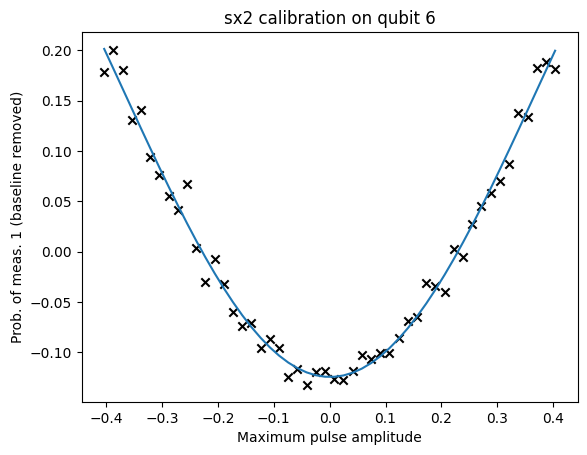

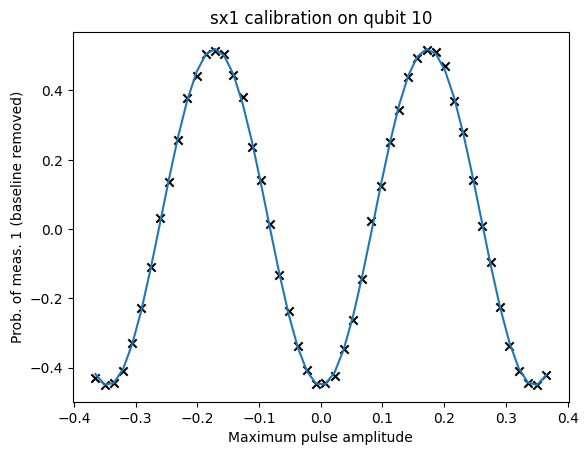

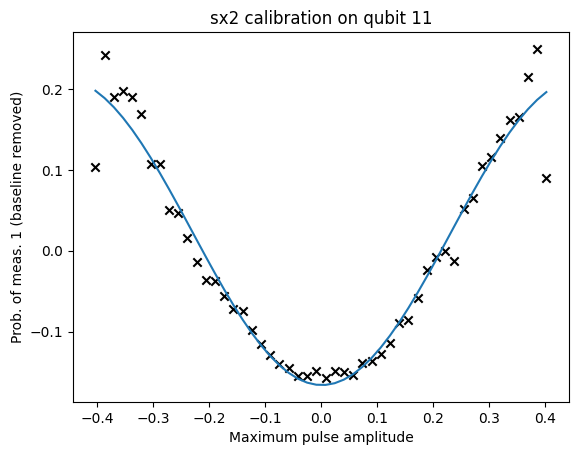

In [603]:
sx_rough_amps = []
for i, (qubit, rabi) in enumerate(zip(qubits, sx_rabi_values)):
    sx_rough_amps.append(get_drive_period(
        rabi, 
        drive_amps, 
        4, 
        gate_name=f"sx{i % 2 + 1}", 
        plot=True, 
        qubit=qubit,
        amplitude_max= sx1_max if i % 2 == 0 else sx2_max,
    ))


In [604]:
for i, (qubit, period) in enumerate(zip(qubits, x_rough_amps)):
    print(f"Qubit {qubit} x{i % 2 + 1} gate period: {period}")

Qubit 1 x1 gate period: 0.4877880578345188
Qubit 2 x2 gate period: 1.3910441359887564
Qubit 5 x1 gate period: 0.5058193631009233
Qubit 6 x2 gate period: 1.4632484222535578
Qubit 10 x1 gate period: 0.4720046154761373
Qubit 11 x2 gate period: 1.262739065848208


In [605]:
for i, (qubit, period) in enumerate(zip(qubits, sx_rough_amps)):
    print(f"Qubit {qubit} sx{i % 2 + 1} gate period: {period}")

Qubit 1 sx1 gate period: 0.29091677600030846
Qubit 2 sx2 gate period: 1.2570094281347826
Qubit 5 sx1 gate period: 0.3036931451996697
Qubit 6 sx2 gate period: 1.090668031879317
Qubit 10 sx1 gate period: 0.2836251462406643
Qubit 11 sx2 gate period: 0.6883349689587329


In [606]:
for i, (x_period, sx_period) in enumerate(zip(x_rough_amps, sx_rough_amps)):
    print(f"Ratio of sx{i % 2} to x{i % 2 + 1} on qubit {qubits[i]}:", sx_period / x_period)

Ratio of sx0 to x1 on qubit 1: 0.5963999555294596
Ratio of sx1 to x2 on qubit 2: 0.9036445326310931
Ratio of sx0 to x1 on qubit 5: 0.6003984176048149
Ratio of sx1 to x2 on qubit 6: 0.7453744800213572
Ratio of sx0 to x1 on qubit 10: 0.6008948576796349
Ratio of sx1 to x2 on qubit 11: 0.545112594973344


## Fine amplitude calibration

We can then use the amplitudes from the rough calibration and further calibrate them using the fine calibration protocol.

In [464]:
def build_schedule(signal, qubit: int, amp: float):
    with qk.pulse.build(backend=backend) as sched:
        signal_samples = ps.resample(
            duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
        )
        gate = ps.scalable_symbolic_pulse(
            duration, signal_samples, "custom", amp=amp
        )
        qk.pulse.play(gate.get_waveform(), qk.pulse.DriveChannel(qubit))
    return sched

In [465]:
def get_fine_experiment(sched, qubit: int, gate: str, backend, x_gate: bool = True):
    inst_map = qk.pulse.InstructionScheduleMap()
    inst_map.add(gate, (qubit,), sched)
    if x_gate:
        exp = qk_e.library.FineXAmplitude((qubit,), backend)
    else:
        exp = qk_e.library.FineSXAmplitude((qubit,), backend)

    exp.set_transpile_options(inst_map=inst_map)
    return exp

We know construct the fine amplitude experiments.

In [466]:
fine_x_experiments = []
fine_sx_experiments = []

for i, (qubit, signal) in enumerate(zip(qubits, x_signals)):
    sched = build_schedule(signal, qubit, x_rough_amps[i])
    exp = get_fine_experiment(sched, qubit, "rabi", backend, x_gate=True)
    fine_x_experiments.append(exp)

for i, (qubit, signal) in enumerate(zip(qubits, sx_signals)):
    sched = build_schedule(signal, qubit, sx_rough_amps[i])
    exp = get_fine_experiment(sched, qubit, "rabi", backend, x_gate=False)
    fine_sx_experiments.append(exp)

And parallelize them like we did with the rough calibration circuits.

In [471]:
x_num_circuits = len(fine_x_experiments[0].circuits())
x_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(x_num_circuits)]
x_crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(x_num_circuits)]
fine_x_circuits = [qk.QuantumCircuit(x_qrs[i], x_crs[i]) for i in range(x_num_circuits)]

sx_num_circuits = len(fine_sx_experiments[0].circuits())
sx_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(sx_num_circuits)]
sx_crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(sx_num_circuits)]
fine_sx_circuits = [qk.QuantumCircuit(sx_qrs[i], sx_crs[i]) for i in range(sx_num_circuits)]

for i, qubit in enumerate(qubits):
    x_circuits = fine_x_experiments[i].circuits()
    sx_circuits = fine_sx_experiments[i].circuits()

    x_schedule = build_schedule(x_signals[i], qubit, x_rough_amps[i])
    sx_schedule = build_schedule(sx_signals[i], qubit, sx_rough_amps[i])

    for j in range(x_num_circuits):
        fine_x_circuits[j].append(x_circuits[j], qargs=(x_qrs[j][qubit],), cargs=(x_crs[j][i],))
        gate = qk.circuit.Gate(f"rabi", 1, [])
        fine_x_circuits[j].add_calibration(gate, (qubit,), x_schedule)
        
    for j in range(sx_num_circuits):
        fine_sx_circuits[j].append(sx_circuits[j], qargs=(sx_qrs[j][qubit],), cargs=(sx_crs[j][i],))
        gate = qk.circuit.Gate(f"rabi", 1, [])
        fine_sx_circuits[j].add_calibration(gate, (qubit,), sx_schedule)

fine_x_circuits = [circuit.decompose() for circuit in fine_x_circuits]
fine_sx_circuits = [circuit.decompose() for circuit in fine_sx_circuits]

In [473]:
fine_x_circuits[3].draw(idle_wires=False)

┌────┐┌───┐┌───┐┌─┐               
 q_1: ┤ √X ├┤ X ├┤ X ├┤M├───────────────
      ├────┤├───┤├───┤└╥┘┌─┐            
 q_2: ┤ √X ├┤ X ├┤ X ├─╫─┤M├────────────
      ├────┤├───┤├───┤ ║ └╥┘┌─┐         
 q_5: ┤ √X ├┤ X ├┤ X ├─╫──╫─┤M├─────────
      ├────┤├───┤├───┤ ║  ║ └╥┘┌─┐      
 q_6: ┤ √X ├┤ X ├┤ X ├─╫──╫──╫─┤M├──────
      ├────┤├───┤├───┤ ║  ║  ║ └╥┘┌─┐   
q_10: ┤ √X ├┤ X ├┤ X ├─╫──╫──╫──╫─┤M├───
      ├────┤├───┤├───┤ ║  ║  ║  ║ └╥┘┌─┐
q_11: ┤ √X ├┤ X ├┤ X ├─╫──╫──╫──╫──╫─┤M├
      └────┘└───┘└───┘ ║  ║  ║  ║  ║ └╥┘
 c: 6/═════════════════╩══╩══╩══╩══╩══╩═
                       0  1  2  3  4  5

And we submit this parallel jobs.

In [474]:
num_shots = 4000 # number extracted from non-parallelized experiments
x_fine_jobs = sampler.run(fine_x_circuits, shots=num_shots)
sx_fine_jobs = sampler.run(fine_sx_circuits, shots=num_shots)

In [475]:
x_fine_jobs.job_id(), sx_fine_jobs.job_id()

('cretg99rmyzg0087318g', 'cretg9hqjh0g008fr7xg')

In [509]:
x_fine_jobs.status(), sx_fine_jobs.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [510]:
x_fine_jobs = service.job("cretg99rmyzg0087318g")
sx_fine_jobs = service.job("cretg9hqjh0g008fr7xg")

To get the experiment results, we have to extract the individual counts for each qubit and experiment, and then put it back together in a way that the experiment framework is able to process it. This is quite complicated and done in the next few cells.

In [511]:
def get_qubit_counts(counts, qubit, num_qubits):
    qubit_counts = {}
    for key, val in counts.items():
        if key[num_qubits - qubit - 1] in qubit_counts:
            qubit_counts[key[num_qubits - qubit - 1]] += val
        else:
            qubit_counts[key[num_qubits - qubit - 1]] = val
    return qubit_counts    

In [512]:
fine_x_metadata = []
for i in range(x_num_circuits):
    fine_x_metadata.append(fine_x_experiments[0].circuits()[i].metadata)

fine_sx_metadata = []
for i in range(sx_num_circuits):
    fine_sx_metadata.append(fine_sx_experiments[0].circuits()[i].metadata)

In [527]:
def reconstruct_data(experiments, job, qubits: list[int], shots: int, metadata: list[dict[str, any]]):
    exp_datas = []
    num_qubits = len(qubits)
    results = job.result()

    for experiment, qubit in zip(experiments, qubits):
        exp_data = qk_e.framework.ExperimentData(experiment=experiment)
    
        experiment_results = []
        for result, meta in zip(results, metadata):
            counts = get_qubit_counts(result.data.c.get_counts(), qubit, num_qubits)
            experiment_result_data = qk.result.models.ExperimentResultData(counts=counts)
            header = qk.qobj.QobjExperimentHeader(metadata=meta)
            experiment_result = qk.result.models.ExperimentResult(
                shots=shots,
                success=True,
                data=experiment_result_data,
                meas_level=2,
                header=header,
            )
            experiment_results.append(experiment_result)

        result = qk.result.Result(
            backend_name=backend.name, 
            backend_version=backend.configuration().backend_version,
            qobj_id="Unknown",
            job_id="Unknown",
            success=True,
            results=experiment_results,
        )
        exp_data.add_data(result)
        experiment.analysis.run(exp_data, replace_results=True)
        exp_datas.append(exp_data)
    
    return exp_datas

In [530]:
fine_x_exp_datas = reconstruct_data(
    experiments=fine_x_experiments,
    job=x_fine_jobs,
    qubits=qubits,
    shots=num_shots,
    metadata=fine_x_metadata,
)

fine_sx_exp_datas = reconstruct_data(
    experiments=fine_sx_experiments,
    job=sx_fine_jobs,
    qubits=qubits,
    shots=num_shots,
    metadata=fine_sx_metadata,
)

In [543]:
def get_fine_amplitude_estimation(data, target_angle: float):
    dtheta = data.analysis_results("d_theta").value.nominal_value
    return target_angle / (target_angle + dtheta)

In [586]:
x_fine_ratios = [get_fine_amplitude_estimation(data, np.pi / 2) for data in fine_x_exp_datas]
x_fine_amps = [x_rough_amps[i] * ratio for i, ratio in enumerate(x_fine_ratios)]

sx_fine_ratios = [get_fine_amplitude_estimation(data, np.pi / 4) for data in fine_sx_exp_datas]
sx_fine_amps = [sx_rough_amps[i] * ratio for i, ratio in enumerate(sx_fine_ratios)]

Qubit 1 pulse x1


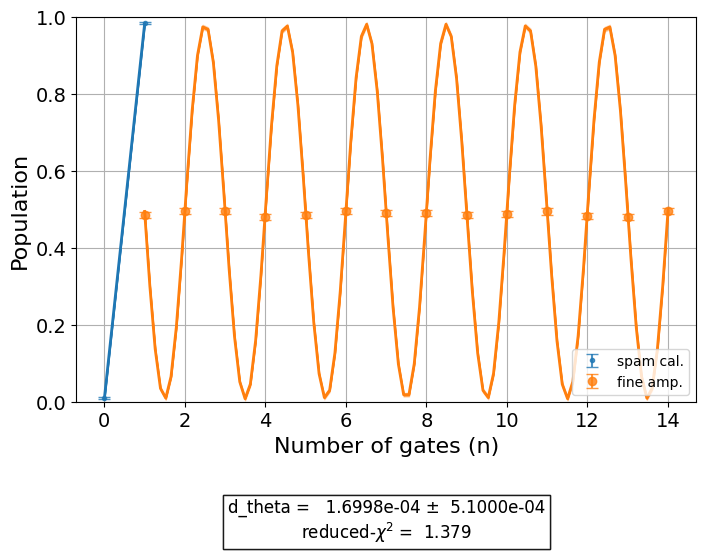

In [612]:
qubit_index = 0
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 2 pulse x2


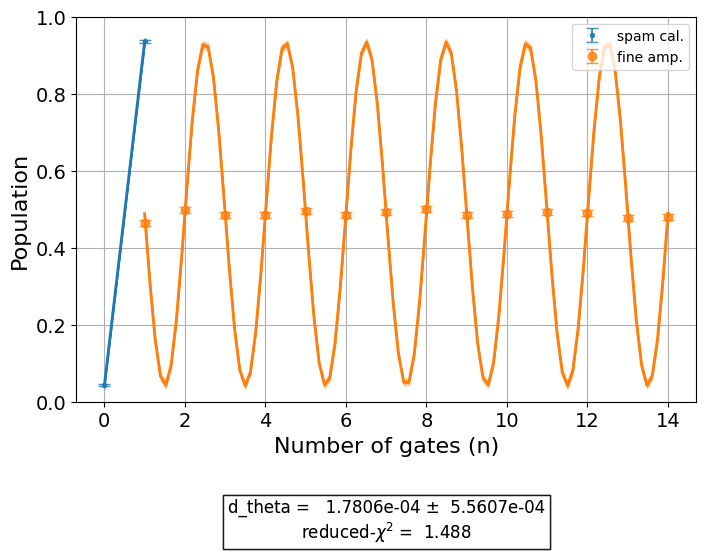

In [613]:
qubit_index = 1
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 6 pulse x2


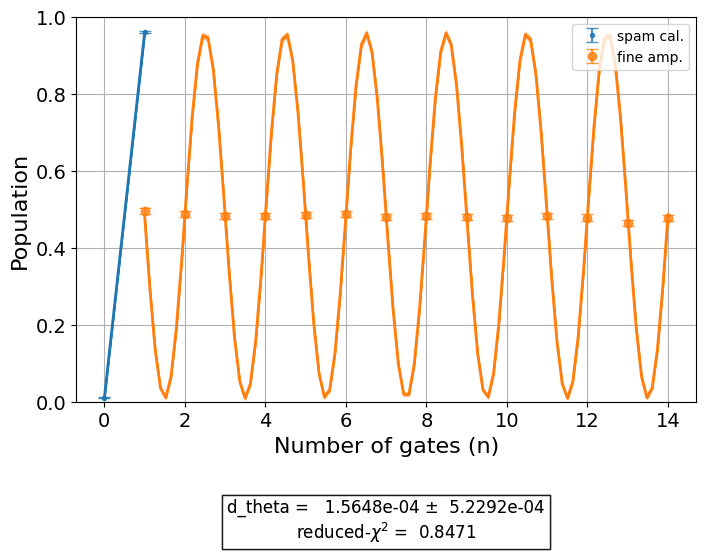

In [614]:
qubit_index = 3
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 10 pulse x1


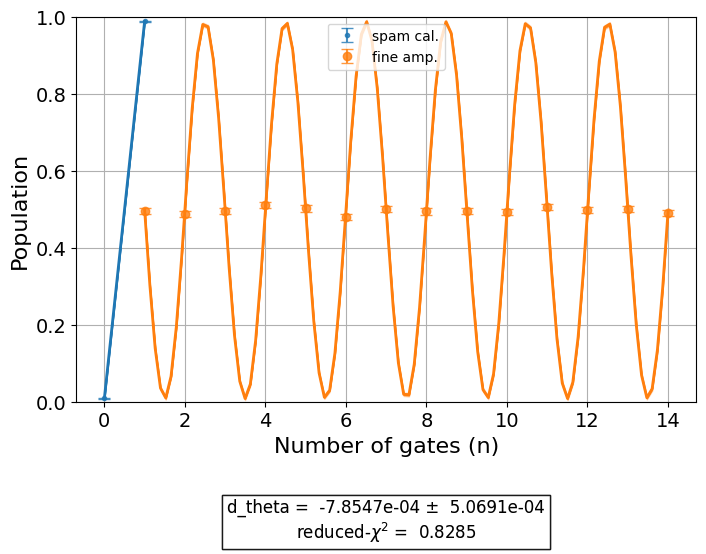

In [615]:
qubit_index = 4
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 11 pulse x2


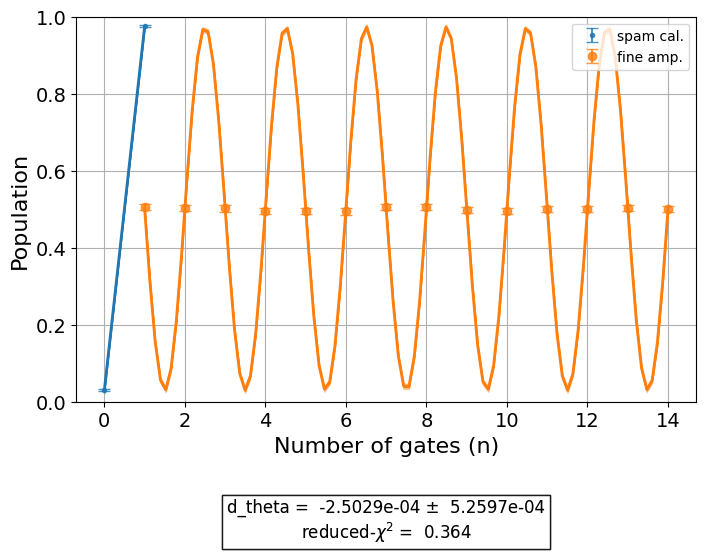

In [616]:
qubit_index = 5
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 1 pulse sx1


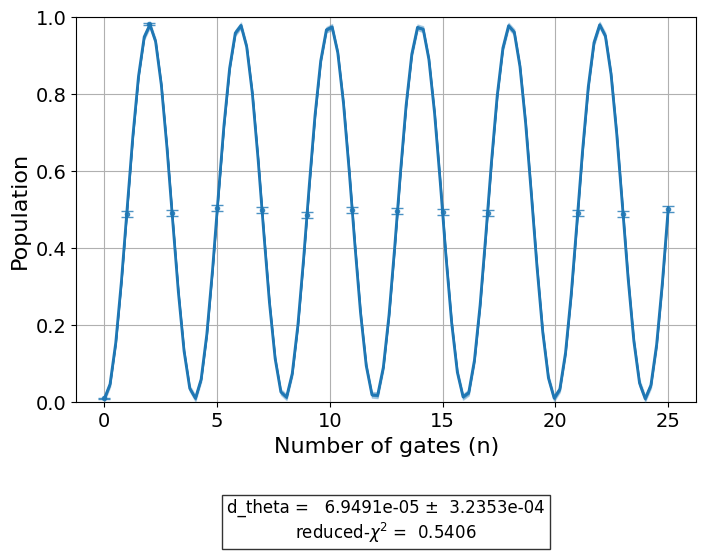

In [617]:
qubit_index = 0
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 2 pulse sx2


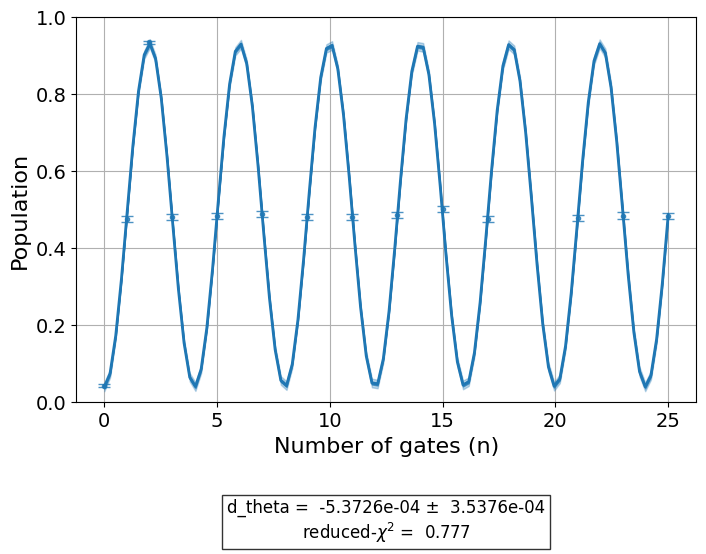

In [618]:
qubit_index = 1
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 5 pulse sx1


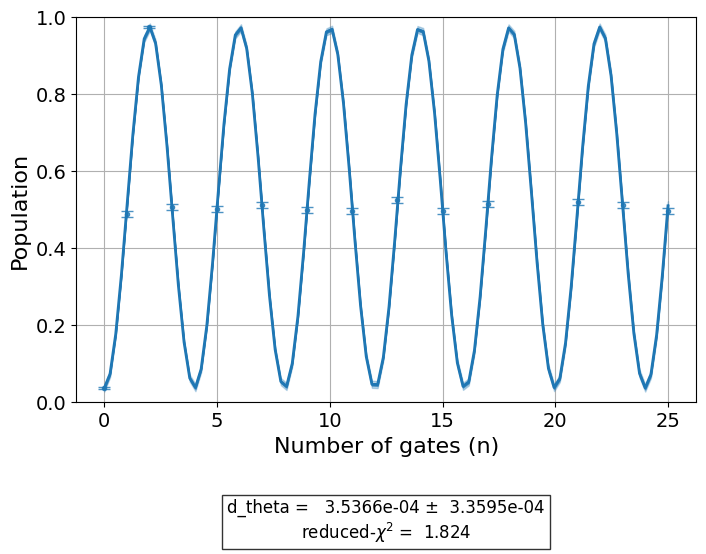

In [619]:
qubit_index = 2
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 6 pulse sx2


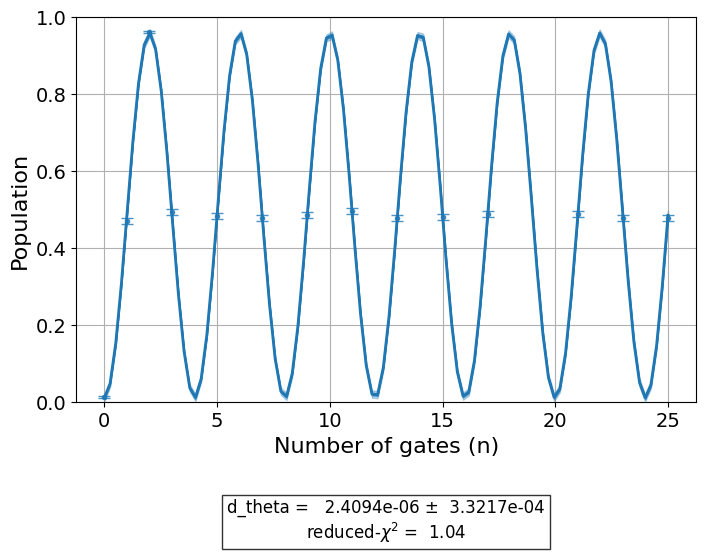

In [620]:
qubit_index = 3
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 10 pulse sx1


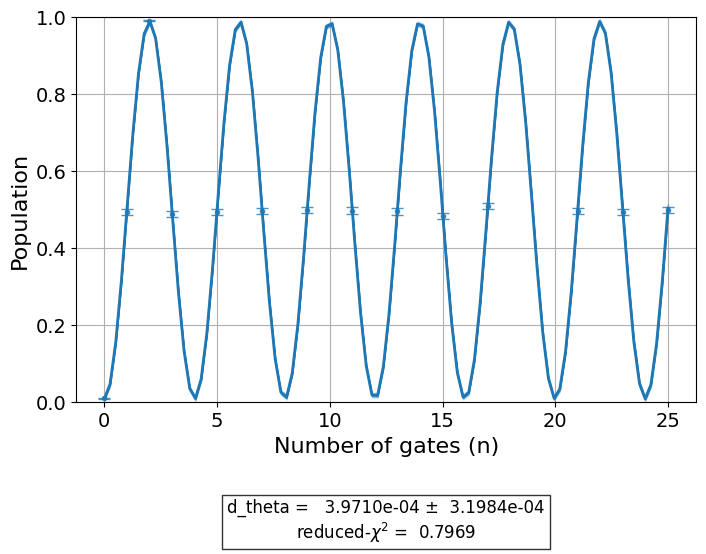

In [621]:
qubit_index = 4
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 11 pulse sx2


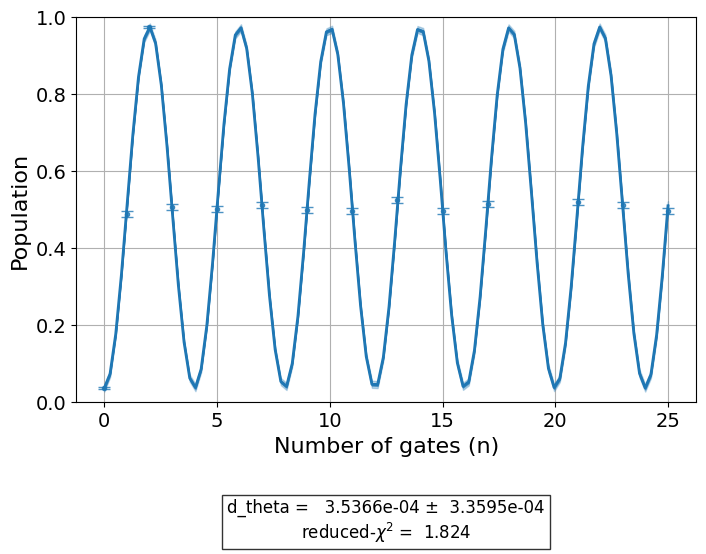

In [622]:
qubit_index = 5
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

We can check the amplitude ratios again after the fine calibration.

In [623]:
for i, (qubit, amp) in enumerate(zip(qubits, x_fine_amps)):
    print(f"Qubit {qubit} x{i % 2 + 1} gate amplitude: {amp}")

Qubit 1 x1 gate amplitude: 0.48773527744051226
Qubit 2 x2 gate amplitude: 1.3908864677755188
Qubit 5 x1 gate amplitude: 0.5058999739970028
Qubit 6 x2 gate amplitude: 1.4631026690468545
Qubit 10 x1 gate amplitude: 0.47224075693259965
Qubit 11 x2 gate amplitude: 1.2629403047390813


In [624]:
for i, (qubit, amp) in enumerate(zip(qubits, sx_fine_amps)):
    print(f"Qubit {qubit} sx{i % 2 + 1} gate amplitude: {amp}")

Qubit 1 sx1 gate amplitude: 0.2908910383202532
Qubit 2 sx2 gate amplitude: 1.2578698827371457
Qubit 5 sx1 gate amplitude: 0.3035564538683344
Qubit 6 sx2 gate amplitude: 1.0906646859634266
Qubit 10 sx1 gate amplitude: 0.2834818166682566
Qubit 11 sx2 gate amplitude: 0.6880251515499476


In [625]:
for i, (x_amp, sx_amp) in enumerate(zip(x_fine_amps, sx_fine_amps)):
    print(f"Ratio of sx{i % 2} to x{i % 2 + 1} on qubit {qubits[i]}:", sx_amp / x_amp)

Ratio of sx0 to x1 on qubit 1: 0.5964117253251839
Ratio of sx1 to x2 on qubit 2: 0.9043656055902894
Ratio of sx0 to x1 on qubit 5: 0.6000325547953731
Ratio of sx1 to x2 on qubit 6: 0.7454464468128853
Ratio of sx0 to x1 on qubit 10: 0.6002908738957413
Ratio of sx1 to x2 on qubit 11: 0.5447804215038422


## Parallel sequence of `x` gates

Now, we are going to choose one of the pairs we calibrated, and run circuits of parallel `x` gates of increasing length.

In [626]:
fine_q0_x1 = build_schedule(pico_gates["x1"], qubits[0], x_fine_amps[0])
fine_q1_x2 = build_schedule(pico_gates["x2"], qubits[1], x_fine_amps[1])

In [631]:
def build_parallel_sequence(num_qubits: int, q0: int, q1: int, schedules: list[qk.pulse.Schedule], length: int):
    qr = qk.QuantumRegister(num_qubits, "q")
    cr = qk.ClassicalRegister(2, "c")
    qc = qk.QuantumCircuit(qr, cr)
    
    x0 = qk.circuit.Gate("x0", 1, [])
    x1 = qk.circuit.Gate("x1", 1, [])

    for _ in range(length):
        qc.append(x0, [q0])
        qc.append(x1, [q1])
        
    qc.measure(qr[q0], cr[0])
    qc.measure(qr[q1], cr[1])
    qc.add_calibration(x0, (q0,), schedules[0])
    qc.add_calibration(x1, (q1,), schedules[1])

    return qc

In [633]:
circuits = []
for i in range(15):
    circuits.append(build_parallel_sequence(num_qubits, qubits[0], qubits[1], [fine_q0_x1, fine_q1_x2], i))

In [636]:
sequence_job = sampler.run(circuits, shots=1024)

In [637]:
sequence_job.job_id()

'crfcja1d7s5g008xwgr0'

Close the session whenever we are done submitting jobs to IBM.

In [601]:
session.cancel()
session.close()
session.status()

'Closed'